ANN parameters with contribution > 2.0%

Optimal constrained:
cluster month            param  cluster_month_pct  signed_cluster_month_pct
     c1   ann      dry_dep_acc          22.284049                -22.284049
     c1   ann            sig_w          13.263680                -13.263680
     c1   ann            bc_ri          11.946067                 11.946067
     c1   ann    prim_so4_diam          10.691105                -10.691105
     c1   ann              dms           5.788167                  5.788167
     c1   ann     carb_ff_diam           3.972128                 -3.972128
     c1   ann autoconv_exp_lwp           2.961935                 -2.961935
     c1   ann           bparam           2.850110                  2.850110
     c1   ann       a_ent_1_rp           2.424258                  2.424258
     c1   ann         cloud_ph           2.203905                  2.203905
     c5   ann      dry_dep_acc          29.417878                -29.417878
     c5   ann            b

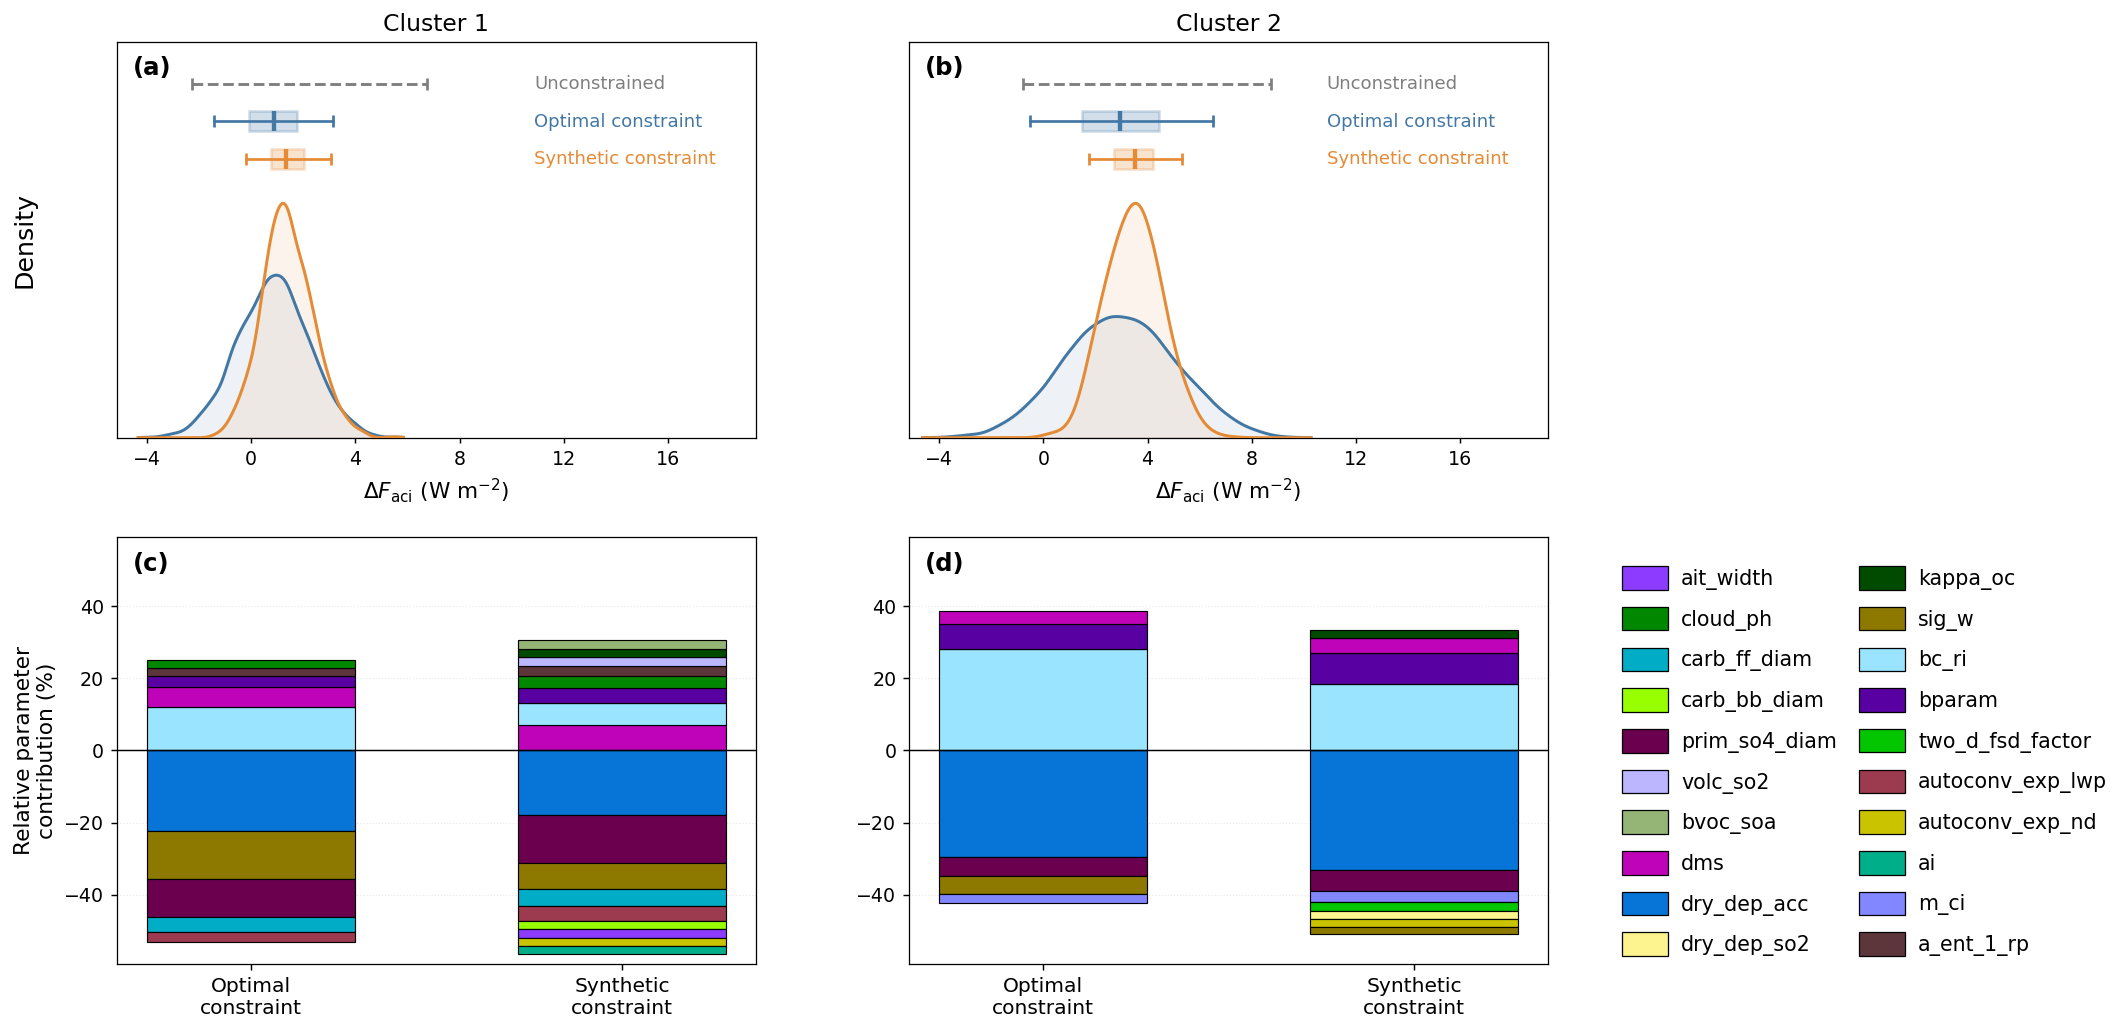

In [9]:
# ============================================================
# 10A. ANN FACI PDF + HORIZONTAL SUMMARIES + >2% PARAMETER FIGURE
#
# Upper row: Cluster 1 and Cluster 2
#   Unconstrained: horizontal P5-P95 line only (no PDF)
#   Optimal / Synthetic: overlapping PDFs and horizontal boxplots
#   Box: P25-P75; centre: P50; whiskers: P5-P95
#   The two clusters use the SAME forcing x-axis range.
#   Left-hand Density label enlarged, moved outward, and aligned with lower ylabel.
#
# Upper PDFs: no x=0 reference line.
# Lower row: original ANN >2% signed parameter contributions.
#   No repeated Cluster titles. Common x/y axis ranges;
#   tightened x-axis so bars occupy more of each panel. Two-column legend.
#
# Updated Fig. 4 method: average forcing over cluster gridpoints
# for EACH 1M variant FIRST, then subset variants and take percentiles.
# Run the updated Cell 1 before this cell.
# Display only: NO files are saved or modified.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator

# ============================================================
# SETTINGS
# ============================================================

ann_clusters = ["c1", "c5"]
ann_threshold = 2.0

pdf_case_names = ["Optimal constraint", "Synthetic constraint"]
summary_case_names = [
    "Unconstrained",
    "Optimal constraint",
    "Synthetic constraint",
]
case_colors = {
    "Unconstrained": "#7F7F7F",
    "Optimal constraint": "#4378A5",
    "Synthetic constraint": "#E58A35",
}

panel_label_fontsize = 13.5
axis_label_fontsize = 12.0
tick_fontsize = 10.5
box_text_fontsize = 10.0

# ============================================================
# CHECK DEPENDENCIES CREATED BY CELL 1
# ============================================================

required_names = [
    "grouped_op", "grouped_final", "grid_df", "op_indices",
    "final_indices_by_cluster", "make_region_tag", "get_forcing_file",
    "sample_size_full", "parameter_names_subset", "param_color_dict",
    "cluster_title_map", "PRINT_MISSING_WARNINGS",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the updated Cell 1 before Cell 2. Missing: "
        + ", ".join(missing_names)
    )

# ============================================================
# ANN >2% PARAMETER CONTRIBUTIONS (UNCHANGED CALCULATION)
# ============================================================

ann_gt2_op = grouped_op[
    (grouped_op["month"] == "ann")
    & grouped_op["cluster"].isin(ann_clusters)
    & (grouped_op["cluster_month_pct"] > ann_threshold)
].copy()

ann_gt2_final = grouped_final[
    (grouped_final["month"] == "ann")
    & grouped_final["cluster"].isin(ann_clusters)
    & (grouped_final["cluster_month_pct"] > ann_threshold)
].copy()

print("=" * 100)
print(f"ANN parameters with contribution > {ann_threshold:.1f}%")
print("=" * 100)
for name, data in [
    ("Optimal constrained", ann_gt2_op),
    ("Final synthetic constrained", ann_gt2_final),
]:
    print(f"\n{name}:")
    print(
        data[[
            "cluster", "month", "param", "cluster_month_pct",
            "signed_cluster_month_pct",
        ]].sort_values(
            ["cluster", "cluster_month_pct"], ascending=[True, False]
        ).to_string(index=False)
    )
print("")

# Common symmetric y-limits for all four bars.
ann_max_stack = 0.0
for cluster_code in ann_clusters:
    for table in (ann_gt2_op, ann_gt2_final):
        values = table.loc[
            table["cluster"] == cluster_code, "signed_cluster_month_pct"
        ].fillna(0.0).to_numpy(dtype=float)
        pos = values[values > 0].sum()
        neg = abs(values[values < 0].sum())
        ann_max_stack = max(ann_max_stack, pos, neg)
ann_bar_ylim = max(1.05 * ann_max_stack, 5.0)

# ============================================================
# ANN CLUSTER-MEAN FACI (UPDATED FIG. 4 ALGORITHM)
# Average gridpoints for each variant FIRST; percentiles SECOND.
# This is NOT mean(gridpoint CI90).
# ============================================================

def compute_ann_cluster_mean_faci(cluster_code, cluster_grid_df, op_idx, final_idx):
    forcing_sum = np.zeros(sample_size_full, dtype=float)
    n_grid_used = 0
    n_missing = 0

    for _, row in cluster_grid_df.iterrows():
        region = make_region_tag(
            cluster_code, row["_lat_dir_use"], row["_lon_dir_use"]
        )
        forcing_file = get_forcing_file("ann", region)
        if not os.path.exists(forcing_file):
            n_missing += 1
            if PRINT_MISSING_WARNINGS:
                print(f"Missing ANN forcing: {forcing_file}")
            continue

        try:
            var_full = np.asarray(
                np.loadtxt(forcing_file), dtype=float
            ).reshape(-1)
            if len(var_full) != sample_size_full:
                raise ValueError(
                    f"Expected {sample_size_full} values, got {len(var_full)}"
                )
            if not np.all(np.isfinite(var_full)):
                raise ValueError("NaN or infinity in ANN forcing")
        except Exception as error:
            n_missing += 1
            if PRINT_MISSING_WARNINGS:
                print(f"Cannot read {forcing_file}: {error}")
            continue

        forcing_sum += var_full
        n_grid_used += 1

    if n_grid_used == 0:
        raise ValueError(f"No valid ANN forcing gridpoints for {cluster_code}")

    cluster_mean_1m = forcing_sum / n_grid_used
    case_values = {
        "Unconstrained": cluster_mean_1m,
        "Optimal constraint": cluster_mean_1m[op_idx],
        "Synthetic constraint": cluster_mean_1m[final_idx],
    }

    case_stats = {}
    for case_name, arr in case_values.items():
        p5, p25, p50, p75, p95 = np.percentile(
            arr, [5, 25, 50, 75, 95]
        )
        case_stats[case_name] = {
            "p5": float(p5),
            "p25": float(p25),
            "p50": float(p50),
            "p75": float(p75),
            "p95": float(p95),
            "ci90": float(p95 - p5),
            "n": len(arr),
        }
    return case_values, case_stats, n_grid_used, n_missing


ann_faci_values = {}
ann_faci_stats = {}
print("=" * 100)
print("ANN cluster-mean FACI: spatial mean first, then P5/P25/P50/P75/P95")
print("=" * 100)
for cluster_code in ann_clusters:
    cluster_grid_df = grid_df[
        grid_df["_cluster_code"] == cluster_code
    ].copy()
    values, stats, n_used, n_missing = compute_ann_cluster_mean_faci(
        cluster_code, cluster_grid_df,
        op_indices, final_indices_by_cluster[cluster_code],
    )
    ann_faci_values[cluster_code] = values
    ann_faci_stats[cluster_code] = stats
    print(f"\n{cluster_title_map[cluster_code]}")
    for case_name in summary_case_names:
        s = stats[case_name]
        print(
            f"  {case_name:<22} "
            f"P5={s['p5']:9.4f}  P25={s['p25']:9.4f}  "
            f"P50={s['p50']:9.4f}  P75={s['p75']:9.4f}  "
            f"P95={s['p95']:9.4f}  CI90={s['ci90']:9.4f}  "
            f"n={s['n']}"
        )
    print(f"  Valid gridpoints: {n_used}; missing/invalid: {n_missing}")
print("")

# ============================================================
# KDE: SAME ABSOLUTE BANDWIDTH FOR OP AND SYNTHETIC, PER CLUSTER.
# Only OP and Synthetic have PDFs; 1M shows ONLY P5-P95.
# ============================================================

def make_kde_curves(case_values, n_x=500):
    op = np.asarray(case_values["Optimal constraint"], dtype=float)
    syn = np.asarray(case_values["Synthetic constraint"], dtype=float)
    values_all = np.concatenate([op, syn])
    x_low, x_high = np.percentile(values_all, [0.1, 99.9])
    span = float(x_high - x_low)
    if span <= 0:
        span = max(abs(float(x_low)) * 0.1, 0.1)
    x_grid = np.linspace(
        x_low - 0.12 * span, x_high + 0.12 * span, n_x
    )
    op_std = float(np.std(op, ddof=1))
    if op_std <= 0:
        raise ValueError("OP forcing distribution has zero variance; KDE undefined")
    bandwidth = op_std * (len(op) ** (-1.0 / 5.0))
    result = {}
    for name, data in [
        ("Optimal constraint", op),
        ("Synthetic constraint", syn),
    ]:
        data_std = float(np.std(data, ddof=1))
        if data_std <= 0:
            raise ValueError(f"{name} forcing distribution has zero variance")
        kde = gaussian_kde(data, bw_method=bandwidth / data_std)
        result[name] = kde(x_grid)
    return x_grid, result

# ============================================================
# PLOT HELPERS
# ============================================================

def draw_horizontal_p50_box(ax, xstats, y, color, height):
    """P5-P95 whiskers, P25-P75 box, P50 (median) centre line."""
    p5, p25, p50, p75, p95 = (
        xstats["p5"], xstats["p25"], xstats["p50"],
        xstats["p75"], xstats["p95"],
    )
    ax.plot([p5, p95], [y, y], color=color, linewidth=1.5, zorder=6)
    cap_height = height * 0.60
    ax.vlines(
        [p5, p95], y - cap_height / 2, y + cap_height / 2,
        colors=color, linewidth=1.5, zorder=7,
    )
    ax.add_patch(Rectangle(
        (p25, y - height / 2), p75 - p25, height,
        facecolor=color, edgecolor=color, alpha=0.24,
        linewidth=1.5, zorder=8,
    ))
    ax.vlines(
        p50, y - height / 2, y + height / 2,
        colors=color, linewidth=2.4, zorder=9,
    )


def draw_horizontal_p5_p95_line(ax, xstats, y, color, cap_height):
    """Unconstrained: dashed P5-P95 range only, with short end caps."""
    ax.plot(
        [xstats["p5"], xstats["p95"]], [y, y],
        color=color, linewidth=1.6, linestyle="--", zorder=6,
    )
    ax.vlines(
        [xstats["p5"], xstats["p95"]],
        y - cap_height / 2, y + cap_height / 2,
        colors=color, linewidth=1.5, zorder=7,
    )


def draw_signed_parameter_bar(ax, data, xpos, bar_width=0.56):
    """Original ANN >2% signed contribution and parameter colors."""
    pos_bottom, neg_bottom = 0.0, 0.0
    sub = data.sort_values("cluster_month_pct", ascending=False)
    for _, row in sub.iterrows():
        value = float(row["signed_cluster_month_pct"])
        color = param_color_dict.get(row["param"], "#808080")
        if value >= 0:
            bottom = pos_bottom
            pos_bottom += value
        else:
            bottom = neg_bottom
            neg_bottom += value
        ax.bar(
            xpos, value, width=bar_width, bottom=bottom,
            color=color, edgecolor="black", linewidth=0.65, zorder=3,
        )

# ============================================================
# COMPUTE COMMON UPPER X-LIMITS FOR THE TWO CLUSTERS
# (include both KDE curves AND 1M P5-P95 endpoints)
# ============================================================

ann_kde_by_cluster = {}
x_limits_candidates = []
for cluster_code in ann_clusters:
    grid_x, pdf_curves = make_kde_curves(ann_faci_values[cluster_code])
    ann_kde_by_cluster[cluster_code] = (grid_x, pdf_curves)
    x_limits_candidates.extend([
        float(grid_x[0]), float(grid_x[-1]),
        ann_faci_stats[cluster_code]["Unconstrained"]["p5"],
        ann_faci_stats[cluster_code]["Unconstrained"]["p95"],
    ])

common_data_left = min(x_limits_candidates)
common_data_right = max(x_limits_candidates)
common_span = common_data_right - common_data_left
if common_span <= 0:
    common_span = max(0.2 * abs(common_data_left), 1.0)

# Make a common label zone on the RIGHT of the data in each upper panel.
label_x = common_data_right + 0.04 * common_span
common_xlim = (
    common_data_left - 0.035 * common_span,
    common_data_right + 0.61 * common_span,
)
# Show x-axis ticks across the ENTIRE displayed axis, including the label area.
common_force_xticks = [
    float(t) for t in MaxNLocator(nbins=7).tick_values(
        common_xlim[0], common_xlim[1]
    )
    if common_xlim[0] <= t <= common_xlim[1]
]

# ============================================================
# LAYOUT: 2x2; wide enough for a two-column parameter legend.
# ============================================================

fig = plt.figure(figsize=(17.2, 8.45), dpi=130)
gs = fig.add_gridspec(
    2, 2, height_ratios=[1.00, 1.08], hspace=0.24, wspace=0.24,
)
axes_top = {
    "c1": fig.add_subplot(gs[0, 0]),
    "c5": fig.add_subplot(gs[0, 1]),
}
axes_bottom = {
    "c1": fig.add_subplot(gs[1, 0]),
    "c5": fig.add_subplot(gs[1, 1]),
}

# ============================================================
# UPPER: OP / SYN PDFs + THREE HORIZONTAL SUMMARIES
# ============================================================

for panel_i, cluster_code in enumerate(ann_clusters):
    ax = axes_top[cluster_code]
    stats = ann_faci_stats[cluster_code]
    x_grid, curves = ann_kde_by_cluster[cluster_code]
    density_max = max(float(np.max(curves[name])) for name in pdf_case_names)

    for case_name in pdf_case_names:
        color = case_colors[case_name]
        density = curves[case_name]
        ax.fill_between(
            x_grid, 0, density, color=color, alpha=0.09, zorder=2,
        )
        ax.plot(
            x_grid, density, color=color, linewidth=1.65, zorder=3,
        )

    # Slightly closer rows, but all remain safely above the PDF peak.
    summary_y = {
        "Unconstrained": 1.51 * density_max,
        "Optimal constraint": 1.35 * density_max,
        "Synthetic constraint": 1.19 * density_max,
    }
    box_height = 0.085 * density_max

    draw_horizontal_p5_p95_line(
        ax, stats["Unconstrained"], summary_y["Unconstrained"],
        case_colors["Unconstrained"], box_height * 0.60,
    )
    for case_name in pdf_case_names:
        draw_horizontal_p50_box(
            ax, stats[case_name], summary_y[case_name],
            case_colors[case_name], box_height,
        )

    for case_name in summary_case_names:
        ax.text(
            label_x, summary_y[case_name], case_name,
            color=case_colors[case_name], ha="left", va="center",
            fontsize=box_text_fontsize, fontweight="medium",
        )

    ax.set_xlim(*common_xlim)  # SAME x-range for c1 and c5.
    ax.set_xticks(common_force_xticks)
    ax.set_ylim(0, 1.69 * density_max)
    ax.set_xlabel(
        r"$\Delta F_{\mathrm{aci}}$ (W m$^{-2}$)",
        fontsize=axis_label_fontsize,
    )
    if panel_i == 0:
        ax.set_ylabel("Density", fontsize=14.0, labelpad=15)
    else:
        ax.set_ylabel("")
    ax.set_yticks([])  # Keep the Density label but no y-axis ticks.
    ax.tick_params(axis="y", left=False, labelleft=False)
    ax.tick_params(
        axis="x", labelsize=tick_fontsize, direction="out", length=3,
    )
    ax.set_title(cluster_title_map[cluster_code], fontsize=13.0, pad=6)
    ax.text(
        0.025, 0.965, f"({chr(97 + panel_i)})",
        transform=ax.transAxes, va="top", ha="left",
        fontsize=panel_label_fontsize, fontweight="bold",
    )

# ============================================================
# LOWER: UNCHANGED ANN >2% SIGNED PARAMETER BARS
# ============================================================

appeared_parameters = set()
for panel_i, cluster_code in enumerate(ann_clusters):
    ax = axes_bottom[cluster_code]
    sub_op = ann_gt2_op[ann_gt2_op["cluster"] == cluster_code].copy()
    sub_final = ann_gt2_final[
        ann_gt2_final["cluster"] == cluster_code
    ].copy()

    draw_signed_parameter_bar(ax, sub_op, xpos=0.0)
    draw_signed_parameter_bar(ax, sub_final, xpos=1.0)

    ax.axhline(0, color="black", linewidth=0.8, zorder=4)
    ax.set_ylim(-ann_bar_ylim, ann_bar_ylim)
    # Tight, identical x-axis limits: two bars fill more of each panel.
    ax.set_xlim(-0.36, 1.36)
    ax.set_xticks([0.0, 1.0])
    ax.set_xticklabels(
        ["Optimal\nconstraint", "Synthetic\nconstraint"], fontsize=11.2,
    )
    ax.tick_params(axis="y", labelsize=tick_fontsize)
    ax.grid(axis="y", linestyle=":", linewidth=0.65, alpha=0.27, zorder=0)
    if panel_i == 0:
        ax.set_ylabel(
            "Relative parameter\ncontribution (%)", fontsize=axis_label_fontsize,
        )
    # No repeated Cluster 1 / Cluster 2 lower titles.
    ax.set_title("")
    ax.text(
        0.025, 0.965, f"({chr(99 + panel_i)})",
        transform=ax.transAxes, va="top", ha="left",
        fontsize=panel_label_fontsize, fontweight="bold",
    )
    appeared_parameters.update(sub_op["param"].dropna().unique())
    appeared_parameters.update(sub_final["param"].dropna().unique())

# ============================================================
# TWO-COLUMN PARAMETER LEGEND, LARGE PATCHES AND FONTS
# ============================================================

legend_params = [
    p for p in parameter_names_subset if p in appeared_parameters
]
print("Parameters appearing in ANN >2% bars:")
print(", ".join(legend_params))
legend_handles = [
    Patch(
        facecolor=param_color_dict[p], edgecolor="black",
        linewidth=0.7, label=p,
    )
    for p in legend_params
]
if legend_handles:
    fig.legend(
        handles=legend_handles,
        loc="center left", bbox_to_anchor=(0.74, 0.29),
        ncol=2, frameon=False, fontsize=11.4,
        handlelength=2.20, handleheight=1.38,
        handletextpad=0.65, columnspacing=1.10, labelspacing=0.83,
    )

fig.subplots_adjust(
    left=0.075, right=0.715, top=0.945, bottom=0.105,
)

# Align the left-hand y-axis labels in the upper and lower panels.
fig.align_ylabels([axes_top["c1"], axes_bottom["c1"]])

# Notebook display only. DO NOT save any image, CSV, or other files.
plt.show()
